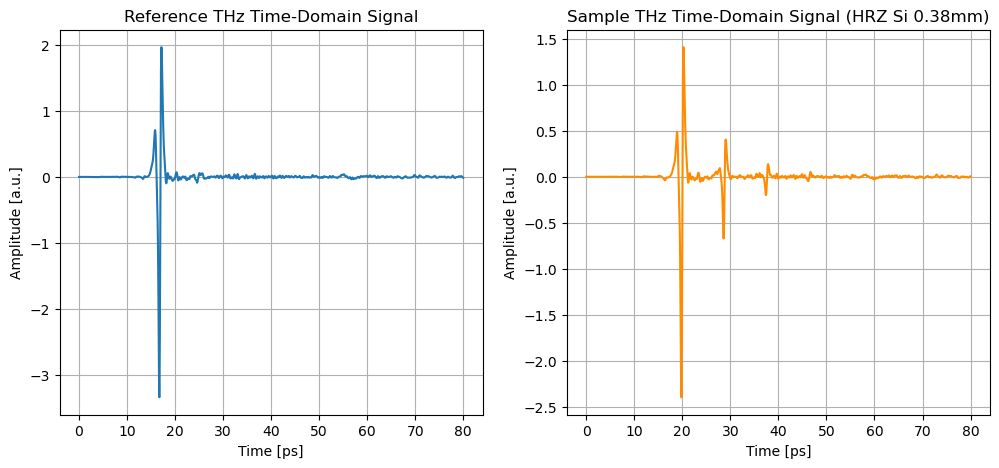

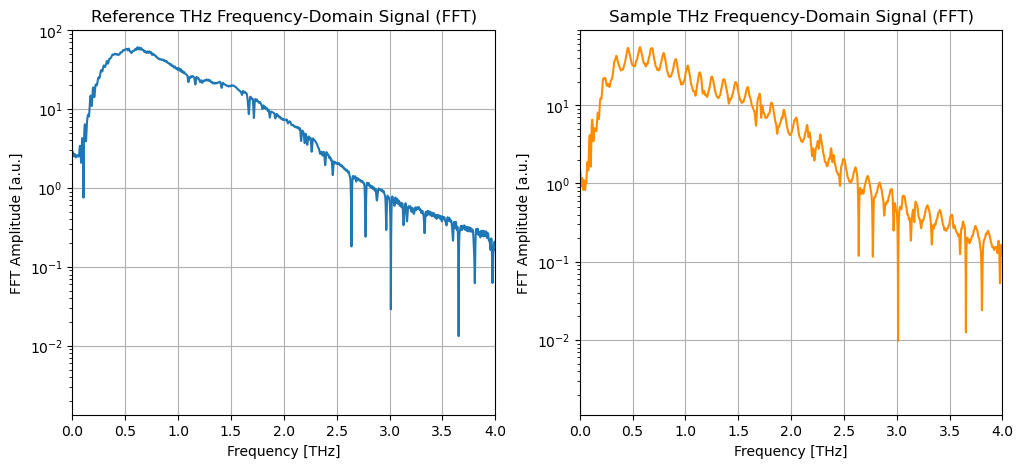

In [16]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy import signal


# INSERT REFERENCE DATA 
reference_pulse = np.loadtxt(r"C:\miniconda_projects\repository\TerahertzProject\TheoTHzTDS\THz-TDS\Transfer Matrix Method\data_06_02_2026\reference_15min_nitrogen.txt",dtype=float)

# INSERT SAMPLE DATA
sample_pulse_HRZ_Si = np.loadtxt(r"C:\miniconda_projects\repository\TerahertzProject\TheoTHzTDS\THz-TDS\Transfer Matrix Method\data_06_02_2026\HRZ_Si_15min_nitrogen.txt",dtype=float)

t1= reference_pulse[:,0] + 740  # ADJUISTING THE AXIS
amp1 = reference_pulse[:,1]
t2 = sample_pulse_HRZ_Si[:,0] + 740  # ADJUISTING THE AXIS
amp2 = sample_pulse_HRZ_Si[:,1]


# FFT OF SIGNALS
reference_fft = np.fft.fft(amp1,65536)
sample_fft = np.fft.fft(amp2,65536)

time_step = t1[1] - t1[0]
frequency = np.fft.fftfreq(65536, d=time_step*1e-12)  # Convert ps to s for frequency calculation

# MASK
mask = (frequency > 0) & (frequency < 5 * 1e12)
reference_fft = reference_fft[mask]
sample_fft = sample_fft[mask]
frequency = frequency[mask]

# PLOTTING REFERENCE AND SAMPLE SIGNALS


# PLOTS
plt.figure(figsize=(12, 5))
plt.subplot(1,2,1)
plt.plot(t1,amp1)
plt.xlabel('Time [ps]')
plt.ylabel('Amplitude [a.u.]')
plt.title('Reference THz Time-Domain Signal')
plt.grid()  
plt.subplot(1,2,2)
plt.plot(t2,amp2, color='darkorange')
plt.xlabel('Time [ps]')
plt.ylabel('Amplitude [a.u.]')
plt.title('Sample THz Time-Domain Signal (HRZ Si 0.38mm)')
plt.grid()
plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(1,2,1)
plt.plot(frequency*1e-12,np.abs(reference_fft))
plt.xlim(0,4)
plt.yscale('log')
plt.xlabel('Frequency [THz]')
plt.ylabel('FFT Amplitude [a.u.]')
plt.title('Reference THz Frequency-Domain Signal (FFT)')
plt.grid()
plt.subplot(1,2,2)
plt.plot(frequency*1e-12,np.abs(sample_fft), color='darkorange')
plt.xlim(0,4)
plt.yscale('log')
plt.xlabel('Frequency [THz]')
plt.ylabel('FFT Amplitude [a.u.]')
plt.title('Sample THz Frequency-Domain Signal (FFT)')
plt.grid()
plt.show()


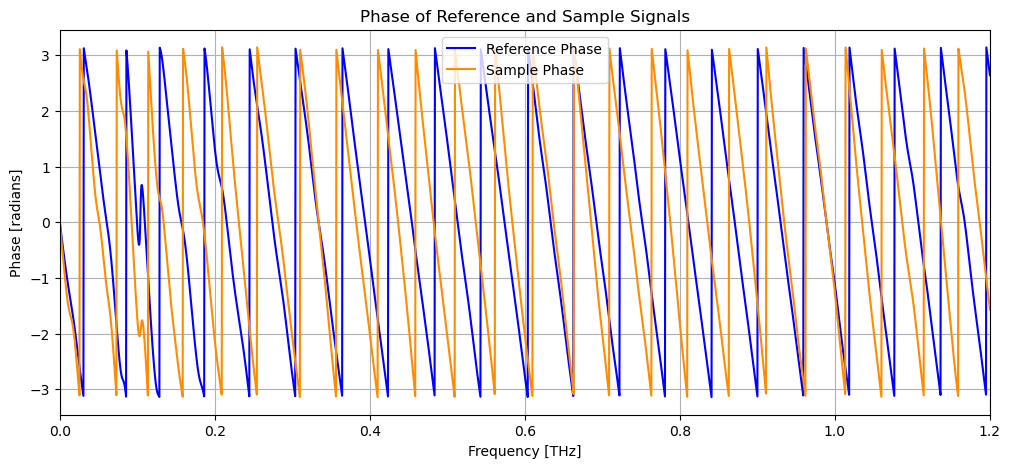

Time delay (ps):  3.069306930000039


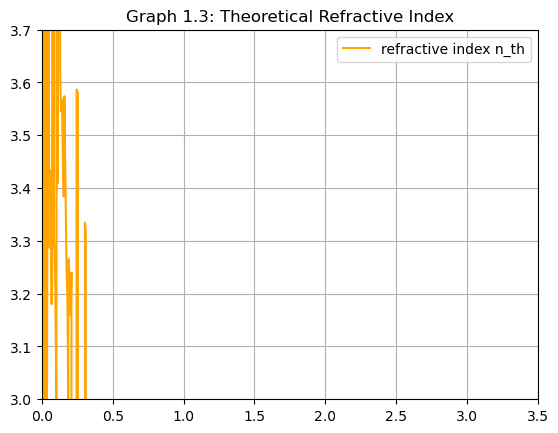

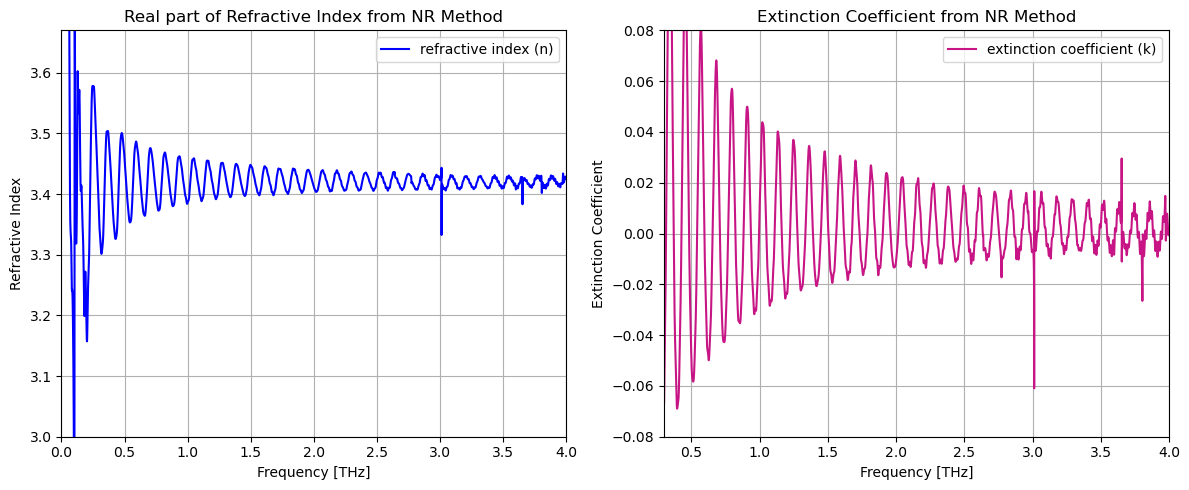

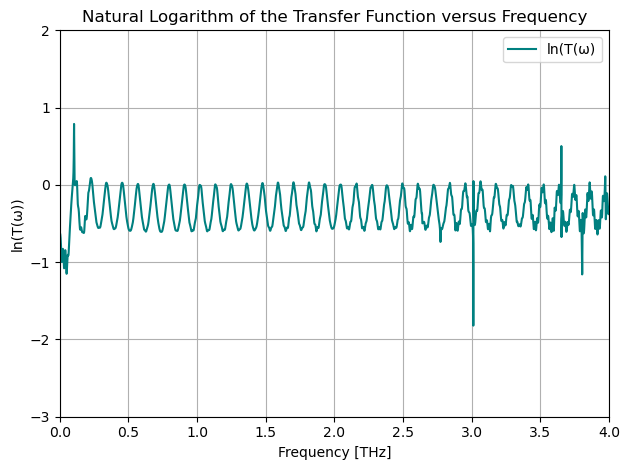

The average value of the real part of the extracted refractive index (n) is: 3.3942161528930535
The average value of the imaginary part of the extracted refractive index (k) is: -0.012955414215490806
The theoretical average real refractive index (n_peaks) is: 3.4231370500000304


In [20]:
# PHASE UNWRAPPING 

phase_ref = np.angle(reference_fft)
phase_sample =np.angle(sample_fft)
delta = phase_sample - phase_ref

plt.figure(figsize=(12, 5))
plt.plot(frequency*1e-12, phase_ref, label='Reference Phase', color='blue')
plt.plot(frequency*1e-12, phase_sample, label='Sample Phase', color='darkorange')
#plt.plot(frequency*1e-12, delta, label='Phase Difference (delta)', color='green')
plt.xlim(0,1.2)
plt.xlabel('Frequency [THz]')
plt.ylabel('Phase [radians]')
plt.title('Phase of Reference and Sample Signals')
plt.legend()
plt.grid()
plt.show()

# TIME DELAY BETWEEN SIGNALS CALCULATION

max_reference_signal = np.max(amp1)
point_in_time_ref = t1[amp1.argmax()]
max_sample_signal = np.max(amp2)
point_in_time_sample = t2[amp2.argmax()]

dt = np.abs(  (point_in_time_sample) -  (point_in_time_ref) ) #time delay in ps
print("Time delay (ps): ", dt)


# REFRACTIVE INDEX CALCULATION

frequency[frequency == 0] = 1e-12  # Replace zeros with a small value to avoid division by zero
c = 3e8 #speed of light in m/s
d = 0.38e-3 #thickness of sample in m
n_0 = 1  # Refractive index of air



# TRANSFER FUNCTION CALCULATION

transfer_signal = sample_fft / reference_fft

transfer_phase = np.angle(sample_fft) - np.angle(reference_fft)
tphase_unwrapped = np.unwrap(transfer_phase)
#tphase_unwrapped -= tphase_unwrapped[0]-0.5*np.pi
ln_transfer = np.log(np.abs(transfer_signal) + 1e-12) + 1j * tphase_unwrapped

# Theoretical refractive index from time delay betweens signal peaks
delta_peaks = point_in_time_sample - point_in_time_ref
delta_peaks_seconds = delta_peaks * 1e-12  # Convert ps to seconds
n_peaks = c * delta_peaks_seconds / d + n_0

refractive = 1 + (np.abs(delta)* c) / (2 * np.pi * frequency * d)

# NEWTON RAPHSON METHOD
def G_zero(n, f, ln_exp):

    ln_th =(np.log((4 * n_0 * n) / (n_0 + n)**2)
             -(1j * 2 * np.pi * f * d / c) * (n - n_0))
    return  ln_th - ln_exp

def G_zerod(n, f):
    p = 1 / n
    m = 2 / (n + n_0) + (1j * 2 * np.pi* f * d) / c 
    return p - m 

def new_raph(n_1, ln_exp, f, iterations, tol):
    n = n_1
    for i in range(iterations): 
        G_zero_ = G_zero(n,  f, ln_exp)
        G_zerod_ = G_zerod(n, f)
        dn = G_zero_ / G_zerod_
        n = n - dn
        if abs(G_zero_/G_zerod_) < tol:
           # print(i, "iterations")
            break
    return n


# INITIAL GUESS AND CALCULATION
n_1 = 3.4 + 0.01j
n_ = []

for i, f in enumerate(frequency, 0):
    ln_exp = np.log(np.abs(transfer_signal[i])) + 1j * tphase_unwrapped[i]
    n_values = new_raph( n_1 ,ln_exp, f,  iterations=70, tol=1e-10)
    n_.append(n_values)


# print("Refractive index values:", n_)
n_ = np.array(n_) 


# PLOTTING REFRACTIVE INDEX AND TRANSFER FUNCTION

# REFRACTIVE INDICES REAL PART
plt.plot(frequency*1e-12, refractive, label='Refractive Index [theoretical]', color='orange')
plt.xlim(xmax = 3.5, xmin = 0)
plt.ylim(ymin=3.0, ymax=3.7)
plt.legend(["refractive index n_th"])
plt.grid(True)
plt.title('Graph 1.3: Theoretical Refractive Index') 


plt.figure(figsize=(12, 5))
plt.subplot(1,2,1)
plt.plot(frequency*1e-12, n_.real, label='Refractive Index [n]', color='blue')
plt.xlim(xmax = 4, xmin = 0)
plt.ylim(ymin=3, ymax=3.67)
plt.legend(["refractive index (n)"])
plt.grid(True)
plt.title('Real part of Refractive Index from NR Method')
plt.xlabel('Frequency [THz]')
plt.ylabel('Refractive Index')

# EXTINCTION COEFFICIENT
plt.subplot(1,2,2)
plt.plot(frequency*1e-12, n_.imag, label='Extinction Coefficient (k)', color='mediumvioletred')
plt.xlim(xmax = 4.0, xmin = 0.3)
plt.ylim(ymin=-0.08, ymax=0.08)
plt.legend(["extinction coefficient (k)"])
plt.title('Extinction Coefficient from NR Method')
plt.xlabel('Frequency [THz]')
plt.ylabel('Extinction Coefficient')

plt.grid(True)
plt.tight_layout()
plt.show()

# NATURAL LOGARITHM OF THE TRANSFER FUNCTION
plt.plot(frequency*1e-12, np.log(np.abs(transfer_signal)), label='Transfer Function Amplitude', color='teal')
plt.xlim(0,4)
plt.ylim(-3, 2)
plt.title('Natural Logarithm of the Transfer Function versus Frequency')
plt.xlabel('Frequency [THz]')
plt.ylabel('ln(T(ω))')
plt.legend(["ln(T(ω)"])
plt.grid(True)
plt.tight_layout()
plt.show()  


print(f"The average value of the real part of the extracted refractive index (n) is: {np.mean(n_.real)}")
print(f"The average value of the imaginary part of the extracted refractive index (k) is: {np.mean(n_.imag)}")   
print(f"The theoretical average real refractive index (n_peaks) is: {np.mean(n_peaks)}")



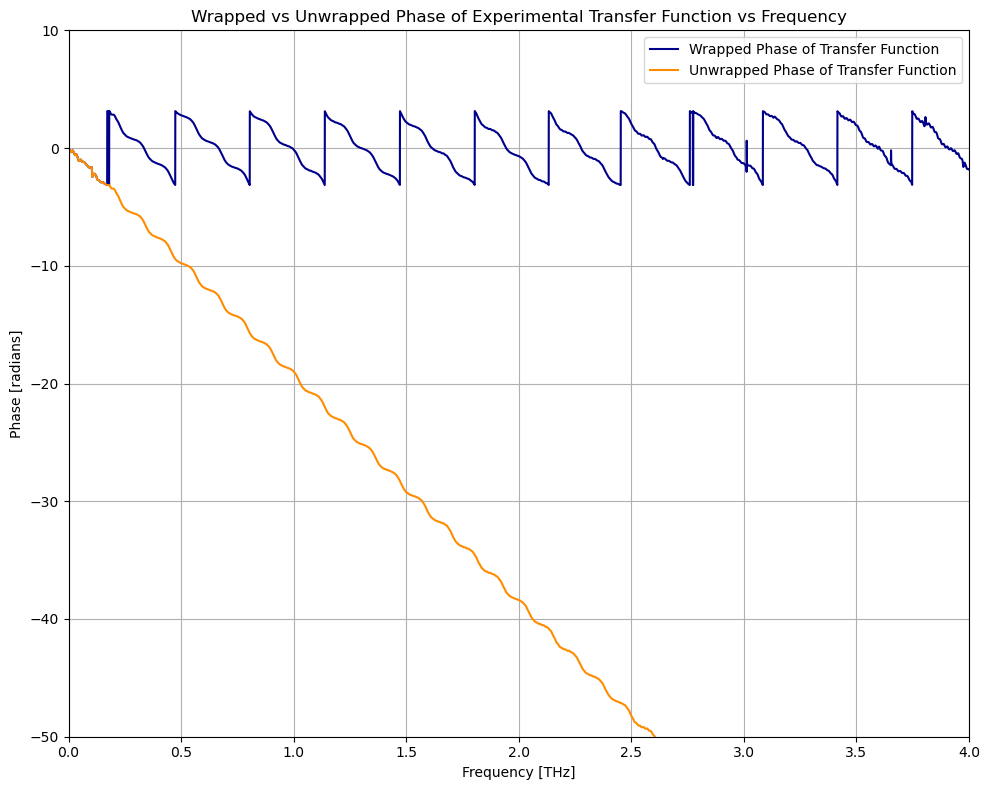

In [18]:
#PLOT WRAPPED PHASE OF TRANSFER FUNCTION

plt.figure(figsize=(10, 8))
plt.plot(frequency*1e-12, np.angle(transfer_signal), label='Wrapped Phase of Transfer Function', color='darkblue')
plt.plot(frequency*1e-12, tphase_unwrapped, label='Unwrapped Phase of Transfer Function', color='darkorange')
plt.xlim(0,4)
plt.ylim(-50,10)
plt.title('Wrapped vs Unwrapped Phase of Experimental Transfer Function vs Frequency')
plt.xlabel('Frequency [THz]')
plt.ylabel('Phase [radians]')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


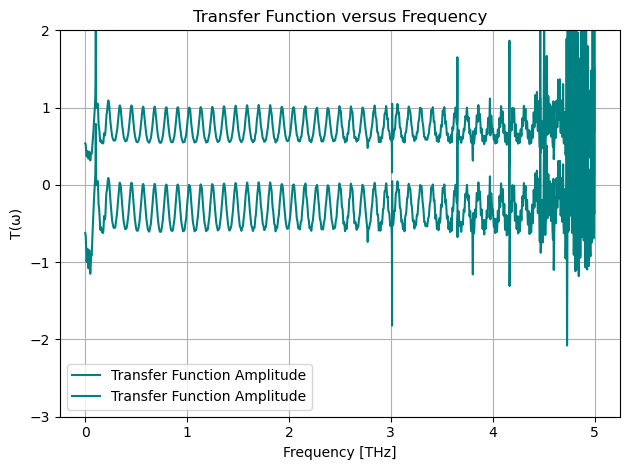

In [22]:
plt.plot(frequency*1e-12,(np.abs(transfer_signal)), label='Transfer Function Amplitude', color='teal')
plt.plot(frequency*1e-12, np.log(np.abs(transfer_signal)), label='Transfer Function Amplitude', color='teal')
plt.ylim(-3, 2)
plt.title('Transfer Function versus Frequency')
plt.xlabel('Frequency [THz]')
plt.ylabel('T(ω)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()  

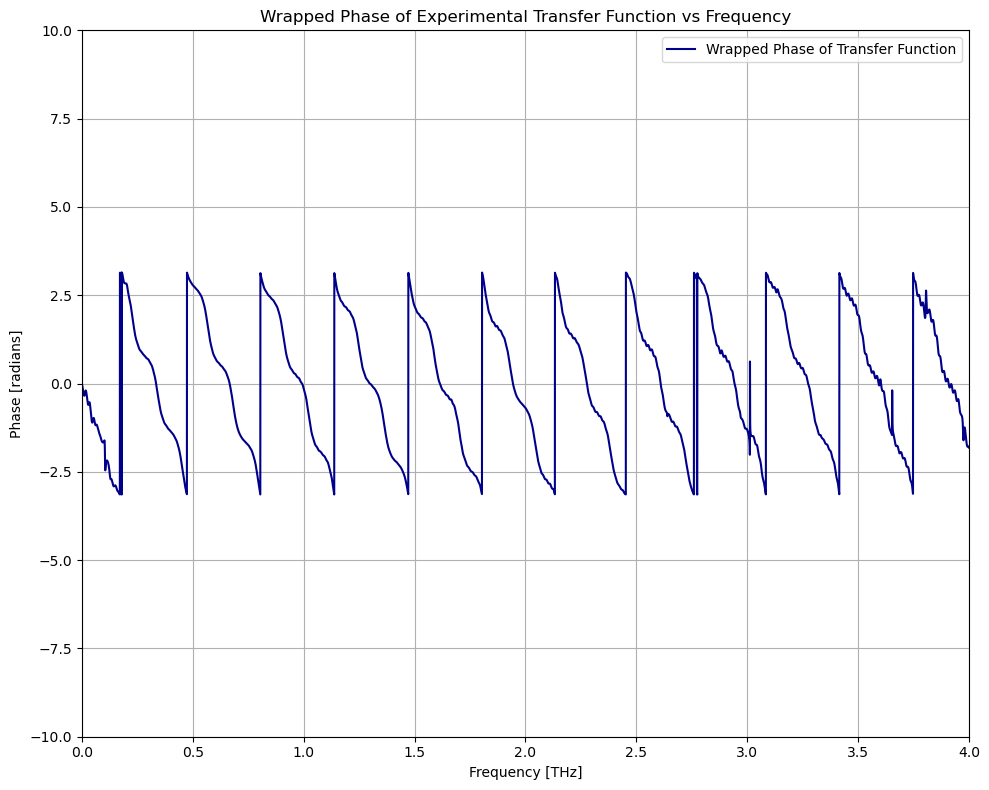

In [24]:
#PLOT WRAPPED PHASE OF TRANSFER FUNCTION

plt.figure(figsize=(10, 8))
plt.plot(frequency*1e-12, np.angle(transfer_signal), label='Wrapped Phase of Transfer Function', color='darkblue')
#plt.plot(frequency*1e-12, tphase_unwrapped, label='Unwrapped Phase of Transfer Function', color='darkorange')
plt.xlim(0,4)
plt.ylim(-10,10)
plt.title('Wrapped Phase of Experimental Transfer Function vs Frequency')
plt.xlabel('Frequency [THz]')
plt.ylabel('Phase [radians]')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
